## Importation des bibliothèques nécessaires

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd
import io
import requests
import numpy as np
import json
from shapely.geometry import shape
np.float = float
np.long = int
import sys
sys.modules["numba"] = None

## Import des données depuis les URLs

Nos 3 sources sont :
- **`df_ips`** : l'indice de position sociale (IPS) de chaque lycée, par année (data.education.gouv.fr) ;
- **`df_res`** : les indicateurs de résultat des lycées généraux et technologiques (taux de réussite, de mentions, d'accès…) (data.education.gouv.fr) ;
- **`df_carte`** : les contours géographiques des départements (ADEME), nécessaires pour les cartes.

In [16]:
url_ips = "https://data.education.gouv.fr/explore/dataset/fr-en-ips_lycees/download/?format=csv&timezone=Europe/Berlin&lang=fr&use_labels_for_header=true&csv_separator=%3B"
url_res = "https://data.education.gouv.fr/explore/dataset/fr-en-indicateurs-de-resultat-des-lycees-gt_v2/download/?format=csv&timezone=Europe/Berlin&lang=fr&use_labels_for_header=true&csv_separator=%3B"
url_carte = "https://data-interne.ademe.fr/data-fair/api/v1/datasets/geo-contours-departements/lines?draft=false&size=10000&finalizedAt=2022-03-02T14:11:30.661Z&page=1&format=csv&sep=;"

df_ips = pd.read_csv(io.StringIO(requests.get(url_ips).text), sep=";")
df_res = pd.read_csv(io.StringIO(requests.get(url_res).text), sep=";")
df_carte = pd.read_csv(url_carte, sep=";") 

df_ips.head(5)

,Rentrée scolaire,Académie,Code du département,Département,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur,Type de lycée,IPS voie GT,IPS voie PRO,IPS Ensemble GT-PRO,Ecart-type de l'IPS voie GT,Ecart-type de l'IPS voie PRO
0,2019-2020,CLERMONT-FERRAND,3.0,ALLIER,0030044G,LYCEE GENERAL BLAISE DE VIGENERE,3254.0,SAINT POURCAIN SUR SIOULE,public,LEGT,109.9,NaN,109.9,34.7,NaN
1,2019-2020,CLERMONT-FERRAND,3.0,ALLIER,0030051P,LYCEE GENERAL ET TECHNOLOGIQUE ALBERT LONDRES ...,3095.0,CUSSET,public,LEGT,109.4,NaN,109.4,35.9,NaN
2,2019-2020,CLERMONT-FERRAND,3.0,ALLIER,0030084A,LYCEE GENERAL PRIVE SAINT BENOIT,3190.0,MOULINS,privé sous contrat,LEGT,105.6,NaN,105.6,37.8,NaN
3,2019-2020,CLERMONT-FERRAND,3.0,ALLIER,0030105Y,LYCEE PROFESSIONNEL PRIVE SAINTE LOUISE,3185.0,MONTLUCON,privé sous contrat,LP,NaN,81.1,81.1,NaN,31.6
4,2019-2020,CLERMONT-FERRAND,3.0,ALLIER,0030905T,LYCEE PROFESSIONNEL GUSTAVE EIFFEL LYCEE DES M...,3118.0,GANNAT,public,LP,NaN,89.2,89.2,NaN,27.5


In [45]:
df_res.head(5)

,Année,UAI,Etablissement,Secteur,Code commune,Commune,Code departement,Département,Académie,Code région,...,Valeur ajoutée du taux de mentions - S2TMD,Valeur ajoutée du taux de mentions - STHR,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T
0,2017,0290108K,LYCEE DUPUY DE LOME (GENERAL ET TECHNO.),public,29019,BREST,29,FINISTERE,RENNES,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017,0290156M,LYCEE ST LOUIS,privé sous contrat,29026,CHATEAULIN,29,FINISTERE,RENNES,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2017,0290174G,LYCEE NOTRE DAME DE KERBERTRA,privé sous contrat,29233,QUIMPERLE,29,FINISTERE,RENNES,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2017,0290177K,LYCEE DU KREISKER,privé sous contrat,29259,ST POL DE LEON,29,FINISTERE,RENNES,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2017,0290181P,LYCEE JAVOUHEY,privé sous contrat,29019,BREST,29,FINISTERE,RENNES,53,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Ici on a importé les deux tableaux dont on a besoin avec l'IPS (indice de position sociale) et les résultats à l'examen du baccalauréat. On ne les a pas importé directement avec pd.read_csv car cela bloquait parfois selon l'environement python du terminal utilisé. Avec la bibliothèque requests adaptée aux API au moins on est sur de ne pas avoir ce problème de versions.
De plus on a importé un shapefile avec les délimitations administratives des départements français pour pouvoir faire des cartes plus tard.

## Nettoyage et mise en forme des données

On cherche à voir quelles variables sont pertinentes pour répondre a notre problématique, pour ce faire, on regarde le nombre de N.A. et le pourcentage de N.A. pour les colonnes qui nous seront potentiellement utiles dans l'analyse des données.

In [ ]:
cols_ips = [
    "UAI", "Rentrée scolaire", "Nom de l'établissment", "Type de lycée", "Secteur",
    "Académie", "Département", "Code du département", "Nom de la commune", "Code INSEE de la commune",
    "IPS voie GT", "Ecart-type de l'IPS voie GT", "IPS Ensemble GT-PRO",
]

cols_res = [
    "UAI", "Année", "Code région", "Code departement", "Département", "Secteur", "Code commune", "Commune",
    "Taux de réussite - Toutes séries", "Taux de mentions - Toutes séries",
    "Valeur ajoutée du taux de réussite - Toutes séries",
    "Taux d'accès 2nde-bac", "Taux d'accès 1ere-bac", "Taux d'accès terminale-bac",
    "Présents - Gnle", "Nombre de mentions TB sans félicitations - G",
    "Taux de réussite - Gnle", "Taux de mentions - Gnle",
    "Taux de réussite - STMG", "Taux de mentions - STMG",
]

cols_carte = ["DDEP_C_COD", "DDEP_L_LIB", "DREG_L_LIB", "geometry"]

for nom, df, cols in [("df_ips", df_ips, cols_ips),
                      ("df_res", df_res, cols_res),
                      ("df_carte", df_carte, cols_carte)]:
    cols_ok = [c for c in cols if c in df.columns]
    resume = pd.DataFrame({
        "NA": df[cols_ok].isna().sum(),
        "% NA": (df[cols_ok].isna().mean() * 100).round(1)
    }).sort_values("NA", ascending=False)
    print(f"--- {nom} ({len(df)} lignes) ---")
    print(resume.to_string())
    print()

--- df_ips (21777 lignes) ---
                                NA  % NA
Ecart-type de l'IPS voie GT  14366  66.0
IPS voie GT                   6985  32.1
Code du département             90   0.4
Code INSEE de la commune        90   0.4
UAI                              0   0.0
Secteur                          0   0.0
Type de lycée                    0   0.0
Nom de l'établissment            0   0.0
Rentrée scolaire                 0   0.0
Nom de la commune                0   0.0
Département                      0   0.0
Académie                         0   0.0
IPS Ensemble GT-PRO              0   0.0

--- df_res (32485 lignes) ---
                                                       NA  % NA
Nombre de mentions TB sans félicitations - G        23892  73.5
Taux de mentions - Gnle                             21558  66.4
Taux de réussite - Gnle                             21558  66.4
Présents - Gnle                                     21558  66.4
Taux de mentions - STMG                      

On voit ici que certaines colonnes ont beaucoup de N.A. mais la plupart des valeurs non renseignées sont dûes a des lycées ayant seulement la filière technologique ou seulement la filière générale. On enlèvera donc simplement les lignes avec ces N.A. quand nécessaire pour les analyses mais pas la peine de supprimer les lignes pour tout le projet.

In [47]:
df_ips[df_ips["Code du département"].isna()].head(5)

,Rentrée scolaire,Académie,Code du département,Département,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur,Type de lycée,IPS voie GT,IPS voie PRO,IPS Ensemble GT-PRO,Ecart-type de l'IPS voie GT,Ecart-type de l'IPS voie PRO
602,2019-2020,CORSE,NaN,CORSE-DU-SUD,6200004K,LYCEE PROFESSIONNEL FINOSELLO AJACCIO,NaN,AJACCIO,public,LP,NaN,86.2,86.2,NaN,27.3
603,2019-2020,CORSE,NaN,HAUTE-CORSE,7200021K,LYCEE GENERAL ET TECHNOLOGIQUE PASCAL PAOLI CORTE,NaN,CORTE,public,LEGT,111.8,NaN,111.8,31.4,NaN
1845,2016-2017,CORSE,NaN,CORSE-DU-SUD,6200001G,LYCEE GENERAL ET TECHNOLOGIQUE FESCH AJACCIO,NaN,AJACCIO,public,LEGT,113.2,NaN,113.2,NaN,NaN
1846,2016-2017,CORSE,NaN,CORSE-DU-SUD,6200002H,LYCEE GENERAL ET TECHNOLOGIQUE LAETITIA BONAPA...,NaN,AJACCIO,public,LEGT,112.5,NaN,112.5,NaN,NaN
1847,2016-2017,CORSE,NaN,CORSE-DU-SUD,6200004K,LYCEE PROFESSIONNEL FINOSELLO AJACCIO,NaN,AJACCIO,public,LP,NaN,87.6,87.6,NaN,NaN


Ici on voit que les résultats au bac des lycées corses sont manquants donc on va enlever ces lignes dans le tableau sur l'IPS. 
Ensuite on va créer une colonne correspondant à l'année dans df_ips pour pouvoir merge les deux tableaux ensemble sur le lycée et l'année scolaire.

In [17]:
df_ips = df_ips[df_ips["Code du département"].notna()]
df_ips["Année"] = df_ips["Rentrée scolaire"].str[-4:].astype(int)
df_ips["Code du département"] = pd.to_numeric(df_ips["Code du département"], errors="coerce").astype("Int64")
df_res["Code departement"] = pd.to_numeric(df_res["Code departement"], errors="coerce").astype("Int64")
df = df_ips.merge(df_res, on=["UAI","Année"], how="left")
df.head(5)

,Rentrée scolaire,Académie_x,Code du département,Département_x,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur_x,Type de lycée,...,Valeur ajoutée du taux de mentions - S2TMD,Valeur ajoutée du taux de mentions - STHR,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T
0,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030044G,LYCEE GENERAL BLAISE DE VIGENERE,3254.0,SAINT POURCAIN SUR SIOULE,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030051P,LYCEE GENERAL ET TECHNOLOGIQUE ALBERT LONDRES ...,3095.0,CUSSET,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030084A,LYCEE GENERAL PRIVE SAINT BENOIT,3190.0,MOULINS,privé sous contrat,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030105Y,LYCEE PROFESSIONNEL PRIVE SAINTE LOUISE,3185.0,MONTLUCON,privé sous contrat,LP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030905T,LYCEE PROFESSIONNEL GUSTAVE EIFFEL LYCEE DES M...,3118.0,GANNAT,public,LP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Pour la suite du projet, on crée de nouvelles variables plus facile a interpréter : 
   - `ecart_selectivite` : taux de réussite moins taux d'accès de la seconde au bac. Plus il est grand, plus le lycée « perd » d'élèves en route ;
   - `taux_TB` : part des mentions Très Bien parmi les présents en voie générale ;
   - `quartile_IPS` : classement des lycées en 4 groupes selon leur IPS (Q1 = les moins favorisés, Q4 = les plus favorisés) ;
   - `taux_mentions_seconde_approx` : approximation du taux de mentions rapporté aux élèves entrés en seconde. 

In [18]:
df["ecart_selectivite"] = df["Taux de réussite - Toutes séries"] - df["Taux d'accès 2nde-bac"]
df["taux_TB"] = df["Nombre de mentions TB sans félicitations - G"] / df["Présents - Gnle"] * 100
df["quartile_IPS"] = pd.qcut(df["IPS voie GT"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
df["taux_mentions_seconde_approx"] = df["Taux de mentions - Toutes séries"] * df["Taux d'accès 2nde-bac"] / 100
df.head(5)

,Rentrée scolaire,Académie_x,Code du département,Département_x,UAI,Nom de l'établissment,Code INSEE de la commune,Nom de la commune,Secteur_x,Type de lycée,...,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T,ecart_selectivite,taux_TB,quartile_IPS,taux_mentions_seconde_approx
0,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030044G,LYCEE GENERAL BLAISE DE VIGENERE,3254.0,SAINT POURCAIN SUR SIOULE,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,16.0,NaN,Q2,59.86
1,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030051P,LYCEE GENERAL ET TECHNOLOGIQUE ALBERT LONDRES ...,3095.0,CUSSET,public,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,8.0,NaN,Q2,46.64
2,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030084A,LYCEE GENERAL PRIVE SAINT BENOIT,3190.0,MOULINS,privé sous contrat,LEGT,...,NaN,NaN,NaN,NaN,NaN,NaN,14.0,NaN,Q2,30.42
3,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030105Y,LYCEE PROFESSIONNEL PRIVE SAINTE LOUISE,3185.0,MONTLUCON,privé sous contrat,LP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-2020,CLERMONT-FERRAND,3,ALLIER,0030905T,LYCEE PROFESSIONNEL GUSTAVE EIFFEL LYCEE DES M...,3118.0,GANNAT,public,LP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Enfin on met juste en forme le tableau avec les données géographiques.

In [19]:
df_carte["geometry"] = df_carte["geometry"].apply(
    lambda x: shape(json.loads(x)) if isinstance(x, str) else x)
df_carte["DDEP_C_COD"] = pd.to_numeric(df_carte["DDEP_C_COD"], errors="coerce").astype("Int64")
df_carte = df_carte.rename(columns={"DDEP_L_LIB":"Département","DDEP_C_COD":"Code du département", "DREG_L_LIB":"Région"})
df_carte = gpd.GeoDataFrame(df_carte, geometry="geometry")
if df_carte.crs is None:
    df_carte = df_carte.set_crs("EPSG:4326")
else:
    df_carte = df_carte.to_crs("EPSG:4326")

cas de la france entière : public vs privé
pourquoi l'ile de france c'est un enjeu 



## À l'échelle de la France : lycées publics vs lycées privés

Nous nous intéressons, pour débuter, aux inégalités scolaires à l'échelle de la France entre lycées publics et lycées privés sous contrat. On comparera ensuite les différentes régions 

In [47]:
df_info_gnle = df[df["Année"]==2022]
df_info_gnle["count"] = 1
df_info_gnle = df_info_gnle.groupby("Secteur_x").agg({"count": "sum", "IPS voie GT": "mean", "Taux de mentions - Toutes séries": "mean", "Taux de réussite - Toutes séries": "mean"}).reset_index()
df_info_gnle.round(1)

<ipython-input-47-af5f988aa41d>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_info_gnle["count"] = 1


,Secteur_x,count,IPS voie GT,Taux de mentions - Toutes séries,Taux de réussite - Toutes séries
0,privé sous contrat,1202,121.6,72.7,98.2
1,public,2390,110.3,58.5,93.7


En 2022, on compte 1 202 établissements privés sous contrat contre 2 390 établissements publics. Le privé accueille en moyenne un public plus favorisé (IPS moyen de 121,6 contre 110,3, soit plus de 11 points d'écart) et affiche de meilleurs résultats : 98,2 % de réussite contre 93,7 %, et surtout 72,7 % de mentions contre 58,5 %. Le taux de réussite est déjà très élevé dans les deux secteurs, c'est donc sur les mentions que l'écart est le plus visible (environ 14 points).

Pour voir comment la réussite au bac varie avec l'origine sociale, on trace une carte de chaleur par secteur (d'abord le public, puis le privé sous contrat). L'IPS des lycées est en abscisse, le taux de réussite en ordonnée, et la couleur indique le nombre d'observations (lycées × années) pour chaque combinaison

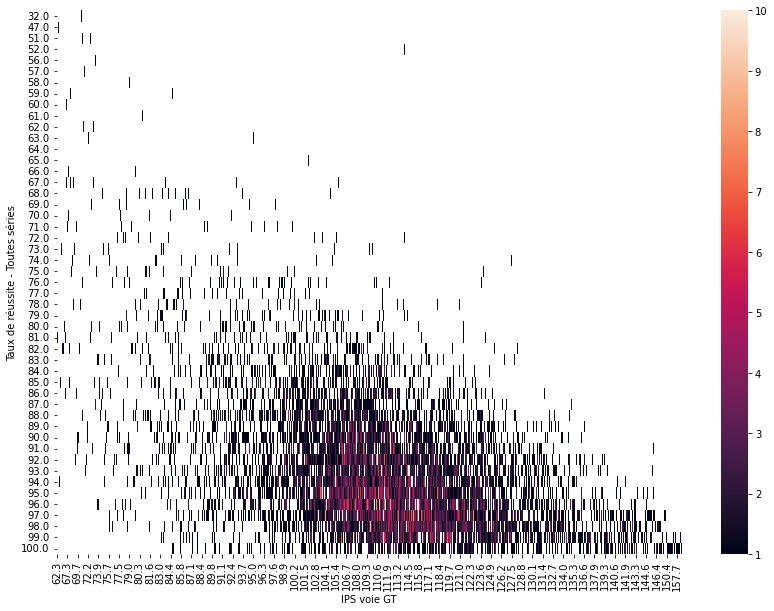

In [44]:
heat_data = df[df["Secteur_x"] == "public"][["IPS voie GT","Taux de réussite - Toutes séries"]]
heat_data["count"] = 1

heat_data = heat_data.groupby(["IPS voie GT", "Taux de réussite - Toutes séries"]).agg({"count": "sum"})
heat_data = heat_data.pivot_table(index = "Taux de réussite - Toutes séries", columns = "IPS voie GT", values = "count", aggfunc="sum")

plt.figure(figsize=(14,10))
ax = sns.heatmap(data=heat_data)

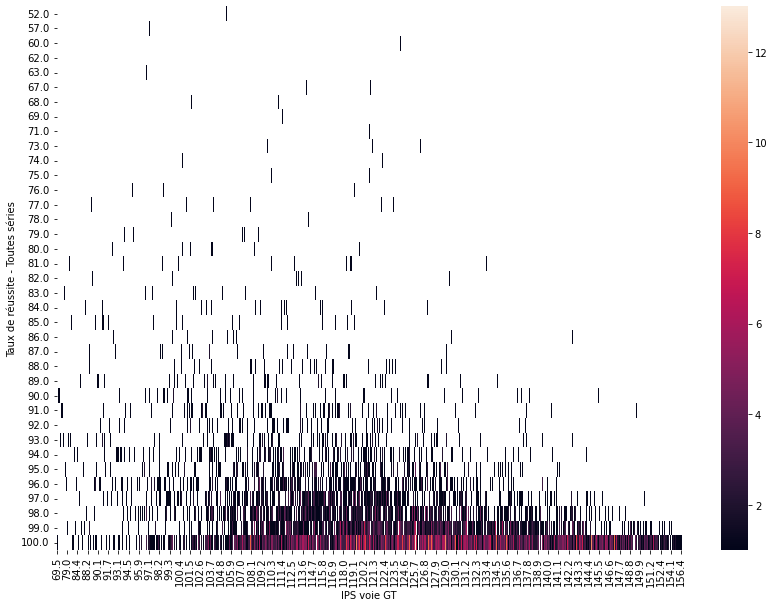

In [43]:
heat_data = df[df["Secteur_x"] == "privé sous contrat"][["IPS voie GT","Taux de réussite - Toutes séries"]]
heat_data["count"] = 1

heat_data = heat_data.groupby(["IPS voie GT", "Taux de réussite - Toutes séries"]).agg({"count": "sum"})
heat_data = heat_data.pivot_table(index = "Taux de réussite - Toutes séries", columns = "IPS voie GT", values = "count", aggfunc="sum")

plt.figure(figsize=(14,10))
ax = sns.heatmap(data=heat_data)

Dans le public, les lycées se concentrent surtout entre 88 % et 100 % de réussite, pour des IPS compris approximativement entre 95 et 125. Quand l'IPS est faible (moins de 85), les observations sont peu nombreuses mais très dispersées, avec des taux de réussite qui peuvent descendre jusqu'à 30-50 %. Plus l'IPS augmente, plus le nuage se resserre vers le haut.
Le privé a une forme proche mais avec plus de réussite : l'essentiel des observations correspond à des IPS plus élevés, avec une forte concentration sur la ligne des 100 % de réussite dès que l'IPS dépasse 100 environ.
Dans les deux secteurs, la réussite augmente avec l'IPS et la dispersion diminue, mais le privé se situe massivement dans la zone « IPS élevé, réussite quasi totale ». Le taux de réussite seul distingue donc peu les lycées, ce qui justifie de regarder ensuite les mentions.

## Au niveau des régions
Après la comparaison nationale, on passe à l'échelle des régions. Pour 2022, on calcule la moyenne de chaque indicateur (IPS, taux de réussite, taux de mentions, taux d'accès de la seconde au bac et taux de mentions Très Bien, avec et sans félicitations) par région et par secteur, puis l'écart entre le public et le privé sous contrat. Cet écart est calculé comme « public moins privé » : une valeur négative signifie que le public est en dessous du privé.
L'« écart moyen » est la moyenne de ces cinq écarts. Il sert d'indicateur de synthèse pour classer les régions, de la plus inégalitaire (la plus négative) à la moins inégalitaire. C'est un outil de lecture rapide, car il additionne des écarts de nature différente (un indice et des pourcentages).

In [20]:
df["taux_TB"] = ((df["Nombre de mentions TB sans félicitations - G"] + df["Nombre de mentions TB avec félicitations - G"]) / df["Présents - Gnle"]) * 100
df_region = df.groupby(["Region","Année","Secteur_x"]).agg({
    "IPS voie GT": "mean",
    "Taux de réussite - Toutes séries": "mean",
    "Taux de mentions - Toutes séries": "mean",
    "Taux d'accès 2nde-bac": "mean",
    "taux_TB": "mean"
}).reset_index()

df_region = df_region[df_region["Année"] == 2022]

df_region_public = df_region[df_region["Secteur_x"]=="public"]
df_region_prive = df_region[df_region["Secteur_x"]=="privé sous contrat"]
df_region_fin = df_region_public.merge(df_region_prive, on=["Region","Année"], suffixes=("_public","_prive"))

df_region_fin["ecart_IPS"] = df_region_fin["IPS voie GT_public"] - df_region_fin["IPS voie GT_prive"]
df_region_fin["ecart_taux_reussite"] = df_region_fin["Taux de réussite - Toutes séries_public"] - df_region_fin["Taux de réussite - Toutes séries_prive"]
df_region_fin["ecart_taux_mentions"] = df_region_fin["Taux de mentions - Toutes séries_public"] - df_region_fin["Taux de mentions - Toutes séries_prive"]
df_region_fin["ecart_taux_acces"] = df_region_fin["Taux d'accès 2nde-bac_public"] - df_region_fin["Taux d'accès 2nde-bac_prive"]
df_region_fin["ecart_taux_TB"] = df_region_fin["taux_TB_public"] - df_region_fin["taux_TB_prive"]

df_region_fin["ecart moyen"] = df_region_fin[["ecart_IPS","ecart_taux_reussite","ecart_taux_mentions","ecart_taux_acces","ecart_taux_TB"]].mean(axis=1)
df_region_fin = df_region_fin.sort_values("ecart moyen", ascending=True)

df_region_fin[["Region","Année","ecart moyen", "ecart_IPS","ecart_taux_reussite","ecart_taux_mentions","ecart_taux_acces","ecart_taux_TB"]].round(1)

,Region,Année,ecart moyen,ecart_IPS,ecart_taux_reussite,ecart_taux_mentions,ecart_taux_acces,ecart_taux_TB
9,LA REUNION,2022,-18.2,-34.3,-5.3,-29.3,-3.4,-18.4
6,GUYANE,2022,-14.6,-30.2,-11.1,-20.7,-5.1,-5.9
8,ILE-DE-FRANCE,2022,-13.9,-21.9,-6.5,-25.9,-2.0,-13.0
7,HAUTS-DE-FRANCE,2022,-8.2,-14.9,-5.1,-13.4,-0.8,-7.1
5,GUADELOUPE,2022,-7.7,-14.0,-3.6,-9.4,-4.4,-6.9
10,MARTINIQUE,2022,-7.6,-15.9,-1.9,-13.8,-0.5,-6.1
15,PROVENCE-ALPES-COTE D'AZUR,2022,-7.1,-10.7,-4.0,-14.0,2.9,-9.7
4,GRA EST,2022,-6.2,-10.6,-4.5,-11.6,2.6,-6.8
3,CENTRE-VAL DE LOIRE,2022,-5.2,-13.9,-2.7,-9.1,5.3,-5.5
12,NOUVELLE-AQUITAINE,2022,-4.6,-6.5,-3.7,-10.0,3.3,-6.3


In [7]:
%pip install folium branca mapclassify matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 430.0 kB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [folium]2m4/5 [folium]x]
Note: you may need to restart the kernel to use updated packages.


In [21]:
df_carte_region = df_carte.dissolve(by="Région", as_index=False)
df_carte_region["Région"] = (
    df_carte_region["Région"]
    .str.normalize("NFKD")
    .str.encode("ascii", errors="ignore")
    .str.decode("utf-8")
    .str.upper()
)

df_carte_region = df_carte_region.merge(df_region_fin, left_on="Région", right_on="Region", how="left")
df_carte_region.explore(column="ecart moyen", cmap="inferno", legend=True, tooltip=["Région","ecart moyen","ecart_IPS","ecart_taux_reussite","ecart_taux_mentions","ecart_taux_acces","ecart_taux_TB"])


Dans toutes les régions, l'écart moyen est négatif : partout, le public a un profil social plus modeste et de moins bons résultats que le privé sous contrat. L'ampleur varie toutefois beaucoup, de -2,7 en Bretagne à -18,2 à La Réunion. Les deux régions d'outre-mer les plus touchées (La Réunion et la Guyane) et l'Île-de-France (-13,9) arrivent en tête, devant les Hauts-de-France (-8,2). En Île-de-France, l'écart d'IPS atteint près de 22 points et l'écart de taux de mentions presque 26 points.
La différence d'écart moyen en Ile de France est très importante pour une région de la France métropolotaine ou il y a plusieurs départements. On comprend déja que l'Ile de france est une région avec des résultats très disperes et interessants pour répondre a notre problématique.

In [23]:
data_idf = df.groupby(["Code departement", "Année"]).agg({"IPS voie GT": "mean", 
                                                     "taux_TB": "mean"}).reset_index()
data_idf = df_carte.merge(data_idf, left_on = "Code du département", right_on= "Code departement", how="left")

data_idf = data_idf[data_idf["Région"] == "Île-de-France"]
data_idf.explore(column="IPS voie GT",cmap="inferno", legend=True, tooltip=["Département","IPS voie GT"])

On voit que les départements de la région Ile de France ont des IPS en voie générale très différent (de 100 a 125), ce qui montre une région avec des étudiants ayant des origines sociales très différentes. L'intérêt de l'Ile de France en tant que région a étudier parait encore plus importante

In [26]:
data_idf.explore(column="taux_TB",cmap="inferno", legend=True, tooltip=["Département","taux_TB"])

On voit bien ici que le taux de mention très bien dans les lycées varie énormement en Ile de France, notament entre Paris et des départements plus pauvres en périphérie de Paris

Après avoir vu toutes ces variables ou l'Ile de France a des valeurs de réussite très disperses, sachant que le mouvement lycéen de 2026 a commencé en Ile de France a Creil, une région ou il y a certain lycées très prestigieux, nous avons décidé de nous interesser particulièrement a cette région qui représente le mieux les inégalités entre les lycées les plus favorisés et les lycées les moins aisés.

## Focus sur le cas de l'île de France

Apres avoir observé ces inégalités a l'échelle nationale, nous concentrons notre étude sur l'Ile de France. Cette région est particulièrement inégalitaire, malgré sa taille plutot réduite. Sur quelque dizaines de kilomètres on trouve à la fois les établissement les plus favorisés et séléctifs de France, mais aussi les départements les plus pauvres.

La ségrégation scolaire et la mixité sociale sont souvent au coeur du débat public, et c'est souvent en Ile de France que ces problèmes sont les plus marqués. Le récent mouvement lycéen est né à Creteil, où les conditions d'études semblent bien loin de celles des lycées parisiens. Pour comprendre comment l'origine sociale pèse sur la réussite au baccalauréat, nous tsructurons cette analyse en 3 étapes, en zoomant petit a petit sur le territoire : 


1. À l'échelle de la région entière, pour mesurer le clivage global entre le secteur public et le secteur privé 

2. À l'échelle des 8 départements franciliens, pour observer la fracture géographique entre Paris, la petite couronne et la grande couronne 

3. À l'échelle des 20 arrondissements de Paris, afin de voir si ces inégalités scolaires se reproduisent au cœur même de la capitale, malgré les dispositifs de mixité sociale mis en place ces dernières années.

Pour mener une analyse fiable sur l'Île-de-France, nous isolons les lycées franciliens sur l'année la plus récente disponible dans nos deux bases. Comme le taux de réussite brut au baccalauréat dépasse aujourd'hui 95 % dans la grande majorité des lycées généraux et technologiques, il ne permet plus vraiment de distinguer les établissements. Nous créons donc une variable mesurant la part des mentions Très Bien (taux_TB), qui reflète mieux l'accès aux filières d'excellence post-bac (comme les classes préparatoires ou les formations très sélectives sur Parcoursup).

In [ ]:
annee = df["Année"].max()
df_idf = df[(df["Code région"] == 11) & (df["Année"] == annee)].drop_duplicates(subset=["UAI"]).copy()

df_idf["code_dep"] = df_idf["Code departement"].astype(str)
df_idf["taux_TB"] = (df_idf["Nombre de mentions TB sans félicitations - G"] / df_idf["Présents - Gnle"]) * 100

cols = [
    "IPS voie GT",
    "Taux de réussite - Toutes séries",
    "Taux de mentions - Toutes séries",
    "Valeur ajoutée du taux de réussite - Toutes séries"
]

I. L'Île-de-France dans son ensemble 


En Île-de-France, près d'un lycéen sur quatre est scolarisé dans le privé sous contrat. L'objectif ici est de comparer le profil social et les résultats médians entre le secteur public et le secteur privé pour voir si les performances affichées par les lycées privés dans les classements bien connus des médias ou sur internet, reflètent un recrutement social différent dès l'entrée en seconde.

In [ ]:
print("Année :", annee)
print(df_idf["Secteur_x"].value_counts())
df_idf.groupby("Secteur_x")[cols].median().round(1)

Année : 2023
Secteur_x
public                308
privé sous contrat    158
Name: count, dtype: int64


,IPS voie GT,Taux de réussite - Toutes séries,Taux de mentions - Toutes séries,Valeur ajoutée du taux de réussite - Toutes séries
Secteur_x,,,,
privé sous contrat,138.0,100.0,85.0,1.0
public,112.2,92.0,49.0,-1.0


En Île-de-France, le secteur privé sous contrat affiche un IPS médian nettement supérieur à celui du public (plus de 20 points d'écart). Si le taux de réussite brut au baccalauréat reste très élevé dans les deux secteurs (autour de 95-98 %), le taux de mentions creuse un écart important en faveur du privé. En revanche, la valeur ajoutée médiane reste très proche de zéro dans les deux cas : les meilleurs résultats bruts du privé s'expliquent avant tout par son recrutement social plus favorisé dès l'entrée en seconde.

Un IPS moyen élevé peut cacher deux réalités très différentes : un lycée homogène où presque tous les élèves viennent de milieux favorisés, ou un lycée véritablement mixte. L'écart-type de l'IPS permet de mesurer cette diversité sociale interne et de vérifier si le secteur public joue davantage un rôle de brassage social que le privé, tout en comparant leur poids respectif dans l'obtention des mentions Très Bien.

In [ ]:
df_idf.groupby("Secteur_x")[["IPS voie GT", "Ecart-type de l'IPS voie GT", "taux_TB"]].median().round(1)

,IPS voie GT,Ecart-type de l'IPS voie GT,taux_TB
Secteur_x,,,
privé sous contrat,138.0,24.6,16.5
public,112.2,33.8,7.1


L'écart-type médian de l'IPS est systématiquement plus élevé dans les lycées publics que dans les lycées privés sous contrat. Cela confirme que l'école publique assure un brassage social nettement plus important en accueillant des élèves d'origines plus variées, là où le secteur privé tend à concentrer un public plus homogène et favorisé. Cette concentration se traduit directement sur l'excellence scolaire : le taux médian de mentions Très Bien est nettement plus élevé dans le privé.

Les moyennes globales d'un lycée masquent souvent de fortes différences entre filières. En Île-de-France comme ailleurs, la voie générale et les filières technologiques (notamment la série STMG, la plus représentée) n'accueillent pas les mêmes profils d'élèves. On compare ici les taux de réussite et de mentions entre la voie générale et la série STMG selon le secteur (public ou privé) pour voir si les écarts se creusent dès que l'on distingue les filières.

In [ ]:
df_idf.groupby("Secteur_x")[["Taux de réussite - Gnle", "Taux de réussite - STMG", "Taux de mentions - Gnle", "Taux de mentions - STMG"]].median().round(1)

,Taux de réussite - Gnle,Taux de réussite - STMG,Taux de mentions - Gnle,Taux de mentions - STMG
Secteur_x,,,,
privé sous contrat,100.0,100.0,86.0,63.5
public,94.0,87.0,56.0,27.0


On observe un double décalage très net. D'une part, quel que soit le secteur, les taux de réussite et de mentions en voie générale dépassent largement ceux de la série STMG (avec un écart particulièrement marqué sur les mentions, souvent supérieur à 25 points). D'autre part, le secteur privé sous contrat conserve un avantage aussi bien en voie générale qu'en série technologique, confirmant que les écarts de performance entre public et privé traversent l'ensemble des filières du lycée.

Dans les classements annuels des lycées publiés par la presse, les établissements sont souvent jugés sur leur taux de mentions. Ce nuage de points permet de visualiser concrètement à quel point la proportion de mentions obtenues par un lycée est liée au milieu social de ses élèves, et comment les établissements privés se positionnent par rapport au public.

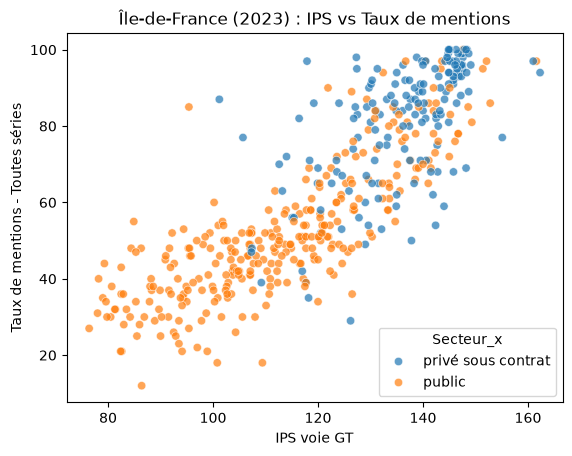

In [ ]:
sns.scatterplot(data=df_idf, x="IPS voie GT", y="Taux de mentions - Toutes séries", hue="Secteur_x", alpha=0.7)
plt.title(f"Île-de-France ({annee}) : IPS vs Taux de mentions")
plt.show()

On observe une relation croissante très nette (quasi linéaire) entre l'IPS d'un établissement et son taux de mentions : plus un lycée accueille d'élèves favorisés, plus la part de bacheliers avec mention augmente. Les points correspondant au privé se concentrent dans la partie supérieure droite du graphique, là où se cumulent fort IPS et fort taux de mentions.

Pour dépasser les classements bruts, la DEPP calcule la valeur ajoutée : elle mesure si un lycée fait mieux ou moins bien que ce qu'on attendait de lui compte tenu du niveau scolaire et social de ses élèves à l'entrée. La ligne rouge à zéro marque cette frontière : ce graphique permet de vérifier si les lycées les plus favorisés apportent réellement une plus-value pédagogique supérieure aux établissements plus populaires.

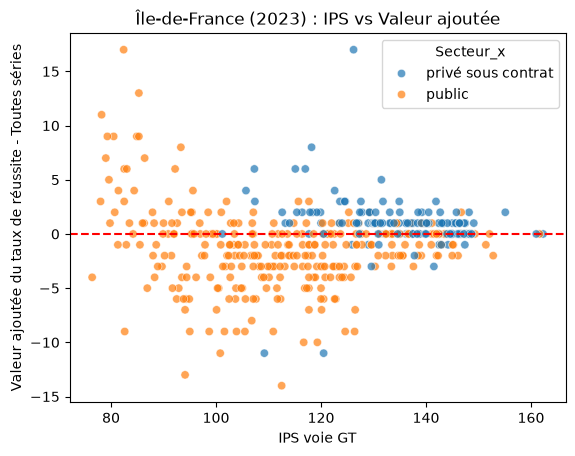

In [ ]:
sns.scatterplot(data=df_idf, x="IPS voie GT", y="Valeur ajoutée du taux de réussite - Toutes séries", hue="Secteur_x", alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.title(f"Île-de-France ({annee}) : IPS vs Valeur ajoutée")
plt.show()

Contrairement à ce que l'on aurait pu attendre si le milieu social expliquait tout, le nuage de points montre que les lycées privés sous contrat se situent majoritairement au-dessus de la ligne rouge 0, tandis que les établissements publics se répartissent un peu plus en dessous. Cela constitue une limite importante à notre hypothèse de départ : même une fois pris en compte le profil social et scolaire des élèves à l'entrée, le secteur privé conserve une valeur ajoutée légèrement positive par rapport au public. Cet écart peut s'expliquer par des facteurs que l'IPS ne capture pas directement, comme l'encadrement pédagogique, les moyens propres des établissements ou encore des pratiques de sélection plus strictes en cours de scolarité.

Pour dépasser les classements bruts, la DEPP calcule la valeur ajoutée : elle mesure si un lycée fait mieux ou moins bien que ce qu'on attendait de lui compte tenu du niveau scolaire et social de ses élèves à l'entrée. La ligne rouge à zéro marque cette frontière : ce graphique permet de vérifier si les lycées les plus favorisés apportent réellement une plus-value pédagogique supérieure aux établissements plus populaires.

In [ ]:
df_idf["ecart_eviction"] = df_idf["Taux de réussite - Toutes séries"] - df_idf["Taux d'accès 2nde-bac"]

df_idf.groupby("Secteur_x")[["Taux de réussite - Toutes séries", "Taux d'accès 2nde-bac", "ecart_eviction"]].median().round(1)

,Taux de réussite - Toutes séries,Taux d'accès 2nde-bac,ecart_eviction
Secteur_x,,,
privé sous contrat,100.0,91.0,8.0
public,92.0,87.0,5.0


Les résultats confirment notre hypothèse : l'écart médian entre le taux de réussite au bac et le taux d'accès de la seconde au bac atteint 8 points dans le privé sous contrat, contre 5 points dans le public. Autrement dit, une plus grande proportion d'élèves entrés en seconde dans le privé quitte l'établissement avant la terminale (par réorientation ou changement de lycée). Cette sélection en cours de scolarité plus marquée explique en partie pourquoi les établissements privés parviennent à maintenir une valeur ajoutée légèrement supérieure à celle du public.

II. Comparaison entre les 8 départements franciliens 

L'Île-de-France est loin d'être un bloc uniforme : les réalités socio-économiques de la Seine-Saint-Denis (93) n'ont rien à voir avec celles des Hauts-de-Seine (92) ou de Paris (75). En classant les 8 départements selon leur IPS moyen, on observe comment la géographie résidentielle de la région se traduit directement dans les résultats au baccalauréat.

In [ ]:
df_idf.groupby(["code_dep", "Département_y"])[cols].mean().round(1).sort_values("IPS voie GT", ascending=False)

,,IPS voie GT,Taux de réussite - Toutes séries,Taux de mentions - Toutes séries,Valeur ajoutée du taux de réussite - Toutes séries
code_dep,Département_y,,,,
75,PARIS,132.8,96.9,74.0,-0.1
78,YVELINES,130.5,96.0,67.6,-1.0
92,HAUTS-DE-SEINE,129.9,95.0,68.1,-1.7
91,ESSONNE,120.1,94.5,59.2,-0.9
94,VAL-DE-MARNE,115.8,94.0,57.7,-0.2
77,SEINE-ET-MARNE,113.1,93.0,54.0,-2.2
95,VAL-D'OISE,112.9,91.5,52.9,-1.8
93,SEINE-SAINT-DENIS,99.2,90.8,47.3,1.6


Le classement des départements met en évidence une fracture territoriale très nette entre le cœur favorisé de l'agglomération et la périphérie : Paris (75) et les Yvelines (78) dominent largement le classement avec les IPS moyens et les taux de mentions les plus élevés, suivis des Hauts-de-Seine (92). À l'opposé, la Seine-Saint-Denis (93) ferme la marche avec un IPS moyen nettement inférieur (plus de 30 points d'écart avec Paris) et un taux de mentions plus faible, tout en conservant une valeur ajoutée moyenne proche de l'équilibre.

La concurrence entre l'école publique et l'école privée ne s'exerce pas de la même manière partout sur le territoire. En calculant l'écart d'IPS entre le privé et le public au sein de chaque département, on identifie les zones où la ségrégation entre les deux secteurs est la plus forte.

In [ ]:
ips_dep = df_idf.pivot_table(index="Département_y", columns="Secteur_x", values="IPS voie GT", aggfunc="mean").round(1)
ips_dep["Ecart"] = ips_dep["privé sous contrat"] - ips_dep["public"]
ips_dep.sort_values("Ecart", ascending=False)

Secteur_x,privé sous contrat,public,Ecart
Département_y,,,
SEINE-SAINT-DENIS,121.8,91.1,30.7
VAL-D'OISE,130.1,106.8,23.3
VAL-DE-MARNE,131.9,108.7,23.2
HAUTS-DE-SEINE,142.3,121.8,20.5
SEINE-ET-MARNE,129.3,109.3,20.0
ESSONNE,134.4,114.9,19.5
YVELINES,143.6,125.2,18.4
PARIS,138.9,126.1,12.8


Les résultats inversent l'intuition de départ : c'est dans les départements les plus populaires que le fossé entre le privé et le public est le plus profond. La Seine-Saint-Denis arrive largement en tête avec un écart de 30,7 points d'IPS entre les deux secteurs (121,8 dans le privé contre 91,1 dans le public), suivie du Val-d'Oise (+23,3) et du Val-de-Marne (+23,2). À l'inverse, Paris affiche l'écart le plus faible de la région (+12,8 points), tout simplement parce que ses lycées publics accueillent déjà un public globalement très favorisé (126,1). Ce classement illustre clairement le mécanisme d'évitement scolaire : plus l'IPS moyen du secteur public est bas dans un département, plus les familles favorisées qui y résident se tournent vers l'enseignement privé sous contrat.

Les inégalités scolaires ne passent pas uniquement par l'opposition entre public et privé : elles existent aussi à l'intérieur même de l'enseignement public. Comparer les lycées généraux et technologiques purs (LEGT) aux lycées polyvalents (LPO, qui accueillent aussi des filières professionnelles) permet de montrer comment la structure de l'établissement influence son recrutement social et son taux de mentions Très Bien.

In [ ]:
df_idf.groupby(["Département_y", "Type de lycée"])[["IPS voie GT", "taux_TB"]].mean().round(1)

IPS voie GT  taux_TB
Département_y     Type de lycée                      
ESSONNE           LEGT                 124.0     11.9
                  LPO                  114.8      7.7
HAUTS-DE-SEINE    LEGT                 133.2     17.5
                  LPO                  114.0      6.5
PARIS             LEGT                 134.5     21.0
                  LPO                  125.1      5.2
SEINE-ET-MARNE    LEGT                 115.7     10.9
                  LPO                  110.7      7.3
SEINE-SAINT-DENIS LEGT                 104.6      9.0
                  LPO                   92.3      5.4
VAL-D'OISE        LEGT                 115.7     10.9
                  LPO                  110.2      7.2
VAL-DE-MARNE      LEGT                 128.5     15.7
                  LPO                  103.6      7.1
YVELINES          LEGT                 134.1     16.7
                  LPO                  121.4      9.6

Dans l'ensemble des départements franciliens, les lycées généraux et technologiques purs (LEGT) affichent un IPS moyen et un taux de mentions Très Bien supérieurs à ceux des lycées polyvalents (LPO). Cela montre qu'au sein même du secteur public, la coexistence avec des filières professionnelles s'accompagne d'un recrutement social plus populaire, même lorsque l'on ne regarde que les élèves inscrits en voie générale et technologique.

Les moyennes départementales peuvent masquer de fortes disparités locales (par exemple, un département globalement favorisé peut abriter des communes très populaires). Ces boxplot permettent de visualiser l'étendue des profils sociaux au sein de chaque département et de comparer la dispersion entre public et privé.

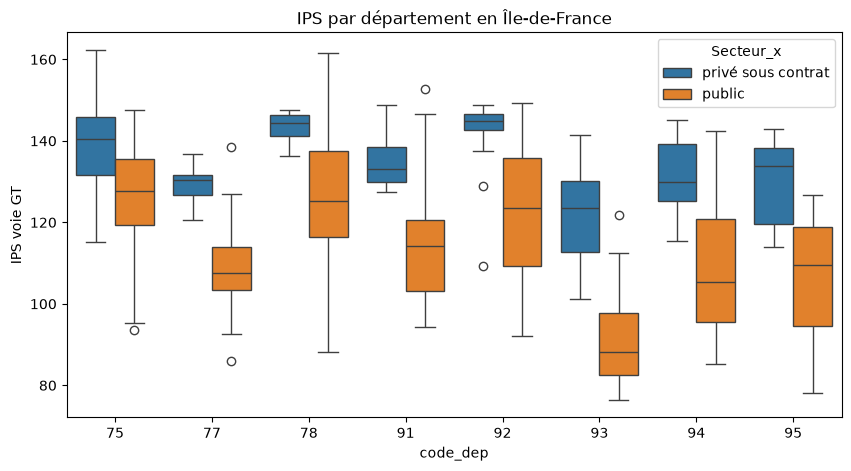

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_idf, x="code_dep", y="IPS voie GT", hue="Secteur_x")
plt.title("IPS par département en Île-de-France")
plt.show()

Dans tous les départements sans exception, la boîte du secteur privé est située nettement au-dessus de celle du public. On remarque toutefois que les Hauts-de-Seine présentent une très forte dispersion dans le public (moustaches très étendues), signe de la coexistence entre des lycées publics d'élite très sélectifs et des lycées publics beaucoup plus mixtes.

Ce graphique met en regard le taux moyen de mentions Très Bien dans chaque département selon le secteur, afin d'illustrer la concentration géographique de l'excellence académique en Île-de-France.

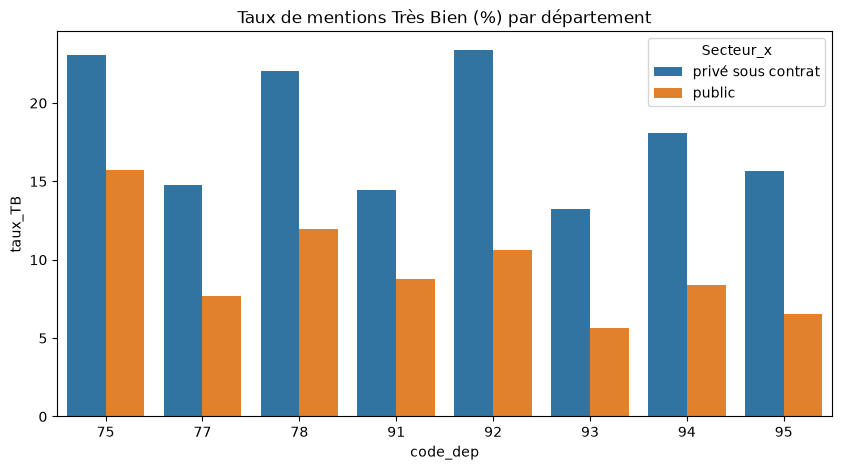

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_idf, x="code_dep", y="taux_TB", hue="Secteur_x", errorbar=None)
plt.title("Taux de mentions Très Bien (%) par département")
plt.show()

La hiérarchie départementale des mentions Très Bien reproduit presque à l'identique celle de l'IPS, confirmant que l'accès aux mentions les plus élevées reste fortement concentré géographiquement dans l'Ouest francilien et à Paris, et porté en grande partie par le secteur privé sous contrat.

III. Zoom sur les 20 arrondissements de Paris 


À l'échelle régionale, Paris apparaît tout en haut du classement comme un département globalement très favorisé. Mais cette moyenne masque une réalité urbaine très contrastée : la capitale reproduit sur un territoire restreint la même fracture sociale que le reste de l'Île-de-France, calquée sur la géographie des quartiers et des prix de l'immobilier. En regroupant les lycées par arrondissement, nous cherchons à vérifier si l'opposition historique entre les arrondissements résidentiels de l'Ouest ou du centre (comme le 6e, le 7e ou le 16e) et les arrondissements plus populaires du Nord-Est (comme le 18e, le 19e ou le 20e) se traduit directement dans les résultats au baccalauréat.

In [ ]:
df_paris = df_idf[df_idf["code_dep"] == "75"].copy()
df_paris["arr"] = df_paris["Code commune"].astype(str).str[-2:].astype(int)

df_paris.groupby("arr")[cols].mean().round(1).sort_values("IPS voie GT", ascending=False)

,IPS voie GT,Taux de réussite - Toutes séries,Taux de mentions - Toutes séries,Valeur ajoutée du taux de réussite - Toutes séries
arr,,,,
7,143.9,99.1,84.1,0.7
5,143.3,99.6,95.0,0.0
6,142.5,99.0,83.0,0.1
4,139.4,99.8,88.5,0.8
16,138.7,98.2,82.1,-0.3
8,138.1,98.7,87.0,0.0
17,136.9,96.1,75.4,-1.7
10,136.0,97.5,77.5,0.0
15,135.2,95.2,73.0,-1.7


Le classement par arrondissement confirme la forte hiérarchie sociale de la capitale, tout en apportant quelques nuances par rapport à la seule opposition Est-Ouest :


En tête du classement, on retrouve les arrondissements historiques de la rive gauche et du centre (7e avec un IPS de 143,9, 5e à 143,3 et 6e à 142,5), suivis du 4e et du 16e. Dans ces quartiers, le taux de réussite frôle les 100 % et plus de 80 % des élèves décrochent une mention (jusqu'à 95,0 % dans le 5e arrondissement, porté par ses grands lycées historiques).

En bas du classement, on retrouve bien les arrondissements populaires du Nord-Est comme le 18e (118,0) ou le 11e (122,4), mais c'est finalement le 14e arrondissement qui affiche l'IPS moyen le plus bas (116,4) ainsi que le taux de mentions le plus faible (48,8 %), notamment en raison du poids des lycées polyvalents et technologiques dans cet arrondissement.

Du côté de la valeur ajoutée, les arrondissements les plus favorisés stagnent autour de zéro, tandis que les arrondissements de l'Est parisien comme le 20e (+2,2) et le 19e (+1,8) affichent les meilleures performances relatives, parvenant à amener près de 97 à 99 % de leurs candidats au baccalauréat malgré un recrutement social plus modeste.

L'offre scolaire parisienne est historiquement très inégalement répartie sur le territoire : certains arrondissements centraux comptent très peu d'établissements, tandis que l'enseignement privé sous contrat est massivement implanté dans les arrondissements de l'Ouest et du Sud-Ouest (6e, 7e, 16e). Ce tableau permet de visualiser cette implantation géographique.

In [ ]:
pd.crosstab(df_paris["arr"], df_paris["Secteur_x"], margins=True)

Secteur_x,privé sous contrat,public,All
arr,,,
3,0,3,3
4,2,2,4
5,2,3,5
6,7,3,10
7,6,1,7
8,1,2,3
9,0,5,5
10,3,1,4
11,2,2,4


Le tableau croisé met en évidence deux déséquilibres dans l'offre scolaire parisienne : d'une part, les arrondissements centraux (1er, 2e, 3e) comptent très peu de lycées ; d'autre part, les établissements privés sous contrat sont fortement concentrés dans les arrondissements favorisés de l'Ouest et de la rive gauche (notamment le 16e, le 6e et le 7e ), ce qui accentue la polarisation sociale entre quartiers.

À Paris, l'attention médiatique se focalise presque toujours sur les mêmes grands lycées historiques (Henri-IV, Louis-le-Grand, Stanislas, Franklin). En classant les établissements parisiens selon leur valeur ajoutée, on met en lumière les lycées — souvent situés dans des arrondissements plus mixtes ou populaires — qui font le plus progresser leurs élèves par rapport à leur niveau de départ.

In [ ]:
cols_top = ["Nom de l'établissment", "arr", "Secteur_x", "IPS voie GT", "Taux de mentions - Toutes séries", "Valeur ajoutée du taux de réussite - Toutes séries"]
df_paris[cols_top].sort_values("Valeur ajoutée du taux de réussite - Toutes séries", ascending=False).head(10)

,Nom de l'établissment,arr,Secteur_x,IPS voie GT,Taux de mentions - Toutes séries,Valeur ajoutée du taux de réussite - Toutes séries
1294,LYCEE GENERAL PRIVE HEIKHAL MENAHEM SINAI,20,privé sous contrat,118.2,35.0,8.0
243,LYCEE POLYVALENT PRIVE SAINT JEAN DE MONTMARTR...,18,privé sous contrat,115.1,56.0,6.0
2208,LYCEE POLYVALENT PRIVE L INITIATIVE,19,privé sous contrat,131.5,61.0,5.0
1714,LYCEE GENERAL PRIVE BETH HANNA,19,privé sous contrat,122.6,65.0,4.0
681,LYCEE POLYVALENT PRIVE CARCADO SAISSEVAL LYCEE...,6,privé sous contrat,134.9,59.0,3.0
1291,LYCEE GENERAL ET TECHNOLOGIQUE PRIVE CHARLES D...,18,privé sous contrat,119.2,86.0,2.0
1705,LYCEE GENERAL ET TECHNOLOGIQUE PRIVE LES PETIT...,19,privé sous contrat,145.8,68.0,2.0
1290,LYCEE POLYVALENT PRIVE SAINT NICOLAS,6,privé sous contrat,138.5,83.0,2.0
684,LYCEE POLYVALENT GUILLAUME TIREL LYCEE DES MET...,14,public,129.3,87.0,2.0
423,LYCEE GENERAL ET TECHNOLOGIQUE HENRI BERGSON,19,public,95.4,27.0,2.0


Ce classement bouscule la hiérarchie habituelle des palmarès médiatiques. On y retrouve certes quelques lycées prestigieux, mais aussi et surtout des établissements situés dans des arrondissements plus populaires ou mixtes (comme le 18e, 19e, 20e ou 13e), qui parviennent à amener la quasi-totalité de leurs élèves au baccalauréat ou à la mention alors que leur IPS d'entrée était modeste.

Enfin, ce dernier nuage de points résume la situation parisienne : il montre dans quelle mesure, au sein même de la capitale, l'accès aux mentions Très Bien reste fortement corrélé à l'origine sociale des élèves de chaque établissement.

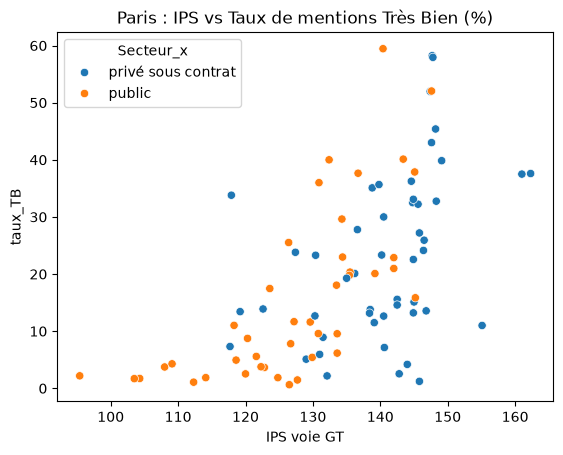

In [ ]:
sns.scatterplot(data=df_paris, x="IPS voie GT", y="taux_TB", hue="Secteur_x")
plt.title("Paris : IPS vs Taux de mentions Très Bien (%)")
plt.show()

Le nuage de points confirme qu'au sein même de la capitale, la proportion de mentions Très Bien augmente fortement avec l'IPS de l'établissement, avec une concentration des lycées privés et des grands lycées publics historiques du Quartier Latin dans le haut de la distribution.

Cette analyse à trois échelles (région, départements, arrondissements parisiens) met en évidence la forte polarisation scolaire de l'Île-de-France. Que l'on regarde la région dans son ensemble, le fossé entre Paris/Hauts-de-Seine et la Seine-Saint-Denis, ou encore la fracture Est-Ouest au sein même de la capitale, la réussite sélective au baccalauréat (et en particulier l'accès aux mentions Très Bien) suit très étroitement la géographie de l'IPS et le clivage entre le public et le privé.
Toutefois, l'étude de la valeur ajoutée permet de nuancer ce constat : si l'origine sociale explique l'essentiel des écarts bruts de mentions, les établissements privés conservent en moyenne une valeur ajoutée légèrement supérieure à celle du public. L'avantage du privé ne repose donc pas uniquement sur son recrutement social plus favorisé, mais aussi sur des dynamiques propres aux établissements (encadrement, climat scolaire ou sélection interne entre la seconde et la terminale) que les seuls indicateurs sociaux ne suffisent pas à résumer.

## Conclusion
Ce projet visait à mesurer comment l'origine sociale des élèves, mesurée par l'IPS, pèse sur la réussite au baccalauréat dans les lycées généraux et technologiques, de la France entière jusqu'aux arrondissements parisiens.

Le lien très net entre IPS et résultats a été démontré a plusieurs niveaux : a toutes les échelles, plus l'IPS d'un lycée est élevé, plus ses résultats le sont. En 2022, le privé sous contrat a un IPS moyen de 121,6 contre 110,3 pour le public. Le taux de réussite est proche du plafond dans les deux secteurs (98,2 % contre 93,7 %), mais l'écart est net sur les mentions (72,7 % contre 58,5 %).

L'Île-de-France concentre ces différences. L'IPS médian du privé (138,0) dépasse de plus de 25 points celui du public (112,2), et le taux de mentions médian passe de 49 % à 85 %. Entre départements, la Seine-Saint-Denis s'oppose à Paris . C'est aussi là que l'écart d'IPS entre privé et public est le plus grand (30,7 points), ce qui suggère un évitement scolaire du public. À Paris, l'IPS va de 143,9 dans le 7e à 116,4 dans le 14e, et les mentions Très Bien suivent l'IPS.

La valeur ajoutée s'est montré particulièrement pertinente. Les écarts bruts s'expliquent surtout par le recrutement social, mais le privé garde une valeur ajoutée médiane légèrement supérieure, peut-être grâce à une sélection en cours de scolarité (8 points d'écart entre réussite et accès seconde-bac, contre 5 dans le public). 

Les données restent tout de même agrégées par lycée : ce sont des corrélations entre établissements, pas des effets individuels. L'IPS ne capture pas tout, et les focus franciliens reposent sur une seule année. L'étude ne capture donc pas tous les effets de réussite